## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

## Cell 2 — Import Libraries

In [ ]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [ ]:
# Download the Cleveland Heart Disease dataset directly from UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak",
    "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

# Convert target to binary:
# 0 = no heart disease, 1-4 = heart disease
df["target"] = (df["target"] > 0).astype(int)

print("Dataset loaded successfully.")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully.
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

The dataset contains 303 patient records and 13 predictor features, plus one binary target variable. The predictor variables include demographic information, clinical measurements, exercise-related measurements, and categorical medical attributes.0 represents absence of heart disease and 1 represents presence of disease. Although many columns have a float64 data type in the raw dataset, several of them are categorical variables represented using numeric codes.

In [ ]:
# TODO: Inspect shape, columns, dtypes, head(), and describe()

print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nDescriptive statistics:")
display(df.describe())

print("\nTarget values:")
print(df["target"].value_counts().sort_index())


Shape: (303, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Descriptive statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000



Target values:
target
0    164
1    139
Name: count, dtype: int64


## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

The target variable is approximately balanced with 54.13% or 164 of samples belonging to class 0 and 45.87% or 139 belonging to class 1. The difference between the two classes is relatively small, so the dataset does not exhibit severe class imbalance. Therefore, accuracy can still be considered alongside precision, recall, and F1-score when evaluating the models. Stratified splitting was used to preserve the class distribution in the training, validation, and test sets.

Class counts:
target
0    164
1    139
Name: count, dtype: int64

Class percentages:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


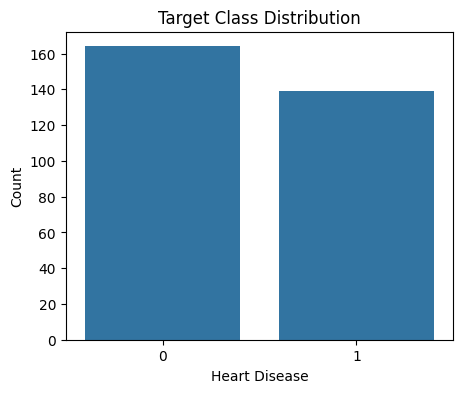

In [ ]:
# Count each target class
class_counts = df["target"].value_counts().sort_index()
class_percent = df["target"].value_counts(normalize=True).sort_index() * 100

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percent.round(2))

plt.figure(figsize=(5, 4))
sns.countplot(x=df["target"])
plt.title("Target Class Distribution")
plt.xlabel("Heart Disease")
plt.ylabel("Count")
plt.show()

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

Missing values are present only in the ca and thal columns, with 4 and 2 missing values respectively. No duplicate rows were found. Although most columns are stored as numeric data types, several variables represent categorical attributes using numerical codes. To avoid losing samples, missing values are imputed during preprocessing rather than removing the affected rows. Numerical variables are handled using median imputation, while categorical variables use most-frequent-value imputation.

In [ ]:
# TODO: Check for missing values, duplicates, dtypes, and unique values per column
print("Missing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nUnique values:")
for column in df.columns:
    print(column, ":", df[column].nunique(), "unique values")

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Number of duplicate rows:
0

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Unique values:
age : 41 unique values
sex : 2 unique values
cp : 4 unique values
trestbps : 50 unique values
chol : 152 unique values
fbs : 2 unique values
restecg : 3 unique values
thalach : 91 unique values
exang : 2 unique values
oldpeak : 40 unique values
slope : 3 unique values
ca : 4 unique values
thal : 3 unique values
target : 2 unique values


## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

The target distribution shows 164 samples without heart disease and 139 samples with heart disease. The two classes are relatively close in size, confirming that the dataset is approximately balanced.
The correlation heatmap shows several variables with noticeable association with the target.The correlation between age and maximum heart rate is also negative. These relationships suggest that multiple features may contribute useful information to the classification task.

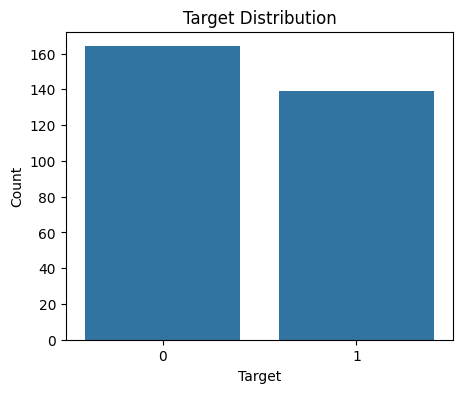

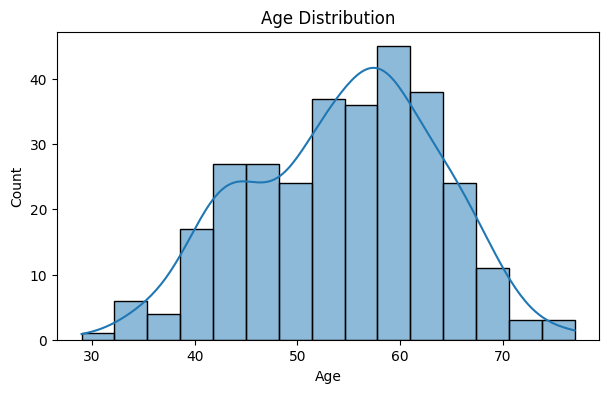

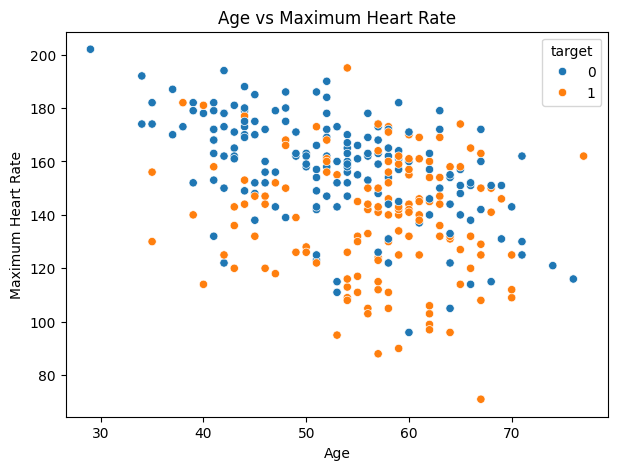

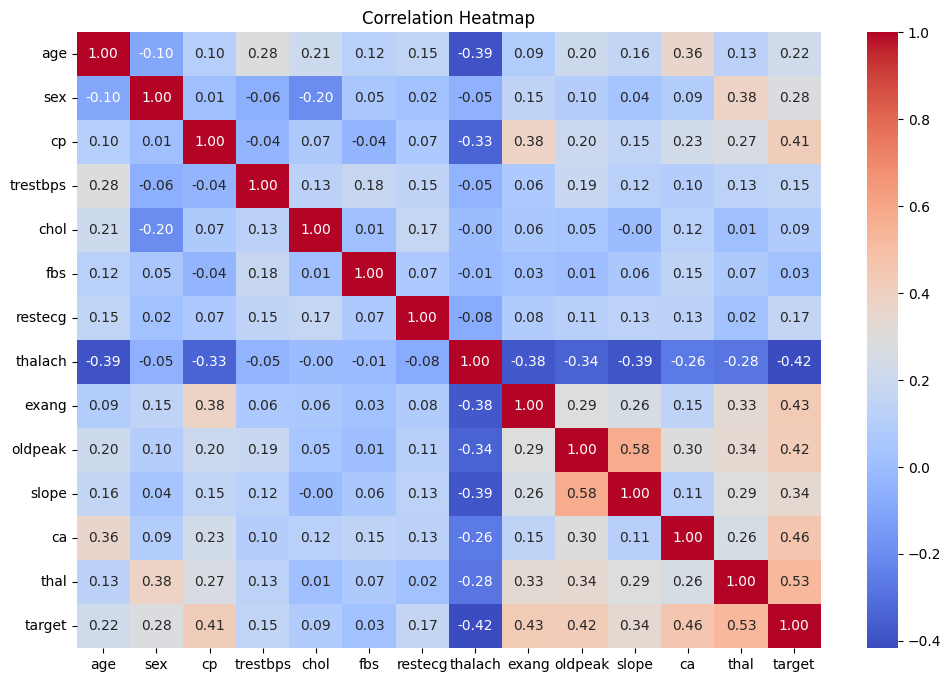

In [ ]:
# TODO: Create the required visualizations
# 1. Target distribution
plt.figure(figsize=(5, 4))
sns.countplot(x=df["target"])
plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

# 2. Age distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", bins=15, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

# 3. Age vs maximum heart rate
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="thalach", hue="target")
plt.title("Age vs Maximum Heart Rate")
plt.xlabel("Age")
plt.ylabel("Maximum Heart Rate")
plt.show()

# 4. Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [ ]:
# Separate features and target
X = df.drop(columns=["target"])
y = df["target"]

numerical_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# First split: development data vs. untouched test data
X_dev_raw, X_test_raw, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: training vs. validation
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_dev_raw,
    y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# IMPORTANT: fit only on training data
X_train_processed = preprocessor.fit_transform(X_train_raw)

# Only transform validation/test data
X_val_processed = preprocessor.transform(X_val_raw)
X_test_processed = preprocessor.transform(X_test_raw)

print("Training samples:", X_train_processed.shape[0])
print("Validation samples:", X_val_processed.shape[0])
print("Test samples:", X_test_processed.shape[0])

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Training samples: 193
Validation samples: 49
Test samples: 61
Processed training shape: (193, 28)
Processed validation shape: (49, 28)
Processed test shape: (61, 28)


In [ ]:
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train.values, dtype=torch.float32
).view(-1, 1)

y_val_tensor = torch.tensor(
    y_val.values, dtype=torch.float32
).view(-1, 1)

y_test_tensor = torch.tensor(
    y_test.values, dtype=torch.float32
).view(-1, 1)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

Fill in the table with your design:

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    |    28     |            |
| Hidden 1 |  16       |      relu      |
| Hidden 2 |    8     |     relu       |
| Hidden 3 |     4   |      relu      |
| Output   |    1    |            |

*(Delete rows you don't use if your design has fewer than 4 hidden layers.)*

In [ ]:
input_size = X_train_processed.shape[1]

print("Input neurons after preprocessing:", input_size)
#neural netwrok design
hidden1 = 16
hidden2 = 8
hidden3 = 4
output_size = 1

print("Architecture:")
print(input_size, "->", hidden1, "->", hidden2, "->", hidden3, "->",output_size)

Input neurons after preprocessing: 28
Architecture:
28 -> 16 -> 8 -> 4 -> 1


## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

Complete the table:

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 |     28      |      16     |  28x16+16  |     464    |
| Hidden 2 |     16      |      8       |  16x8+8   |       136  |
| Hidden 3 |     8      |      4        |    8*4+4  |     36       |
| Output   |      4     |       1       |     4*1+1      |    5      |
| **Total**|             |               |             |       641   |

Later, compare this total to what `model.summary()` reports in Cell 11.

## Cell 11 — Implement Neural Network in PyTorch


In [ ]:
class MyModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 4),
            nn.ReLU(),

            nn.Linear(4, 1)
        )

    def forward(self, x):
        return self.model(x)


model = MyModel(input_size)

print(model)
print("\nTotal trainable parameters:", sum(p.numel() for p in model.parameters()))

MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=4, bias=True)
    (5): ReLU()
    (6): Linear(in_features=4, out_features=1, bias=True)
  )
)

Total trainable parameters: 641


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [ ]:
loss_function = nn.BCEWithLogitsLoss()

print(loss_function)

BCEWithLogitsLoss()


BCEWithLogitsLoss because the target contains two classes, 0 and 1. The loss combines the sigmoid operation and binary cross-entropy into a single numerically stable function. Therefore, the network can output raw logits without requiring a separate sigmoid layer during training.

## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(optimizer)

#We use the Adam optimizer because it is simple to use and adjusts the learning rate for the model parameters during training.

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## Cell 14 — Compile the Model

In [ ]:
num_epochs = 100
history = {
    "train_loss": [],
    "val_loss": []
}

for epoch in range(num_epochs):

    # Training
    model.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = loss_function(outputs, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    train_loss = total_train_loss / len(train_loader)

    # Validation
    model.eval()

    with torch.no_grad():
        val_outputs = model(X_val_tensor)
        val_loss = loss_function(val_outputs, y_val_tensor).item()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(
            "Epoch:", epoch + 1,
            "Train Loss:", round(train_loss, 4),
            "Val Loss:", round(val_loss, 4)
        )

Epoch: 10 Train Loss: 0.6519 Val Loss: 0.6598
Epoch: 20 Train Loss: 0.6114 Val Loss: 0.5902
Epoch: 30 Train Loss: 0.5274 Val Loss: 0.5299
Epoch: 40 Train Loss: 0.5315 Val Loss: 0.5043
Epoch: 50 Train Loss: 0.5066 Val Loss: 0.4831
Epoch: 60 Train Loss: 0.4868 Val Loss: 0.4738
Epoch: 70 Train Loss: 0.4682 Val Loss: 0.4667
Epoch: 80 Train Loss: 0.3745 Val Loss: 0.4636
Epoch: 90 Train Loss: 0.3612 Val Loss: 0.4608
Epoch: 100 Train Loss: 0.4177 Val Loss: 0.4749


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

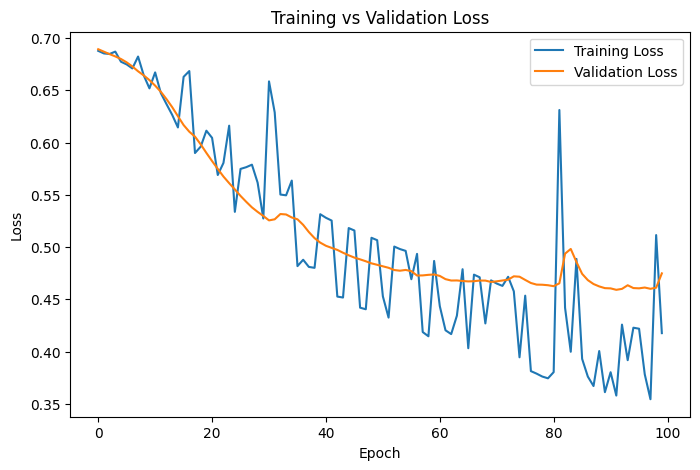

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

#not overfitting as val loss is not increasing,and training loss also changes,if overfitting train loss will decrease and val loss increases. However after 90 epochs val loss comes to flat/inc abit so overfitting may be beggining mildly.

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [ ]:
model.eval()

with torch.no_grad():
    test_outputs = model(X_test_tensor)
    test_probabilities = torch.sigmoid(test_outputs)

y_prob_nn = test_probabilities.numpy().ravel()
y_pred_nn = (y_prob_nn >= 0.5).astype(int)
y_true = y_test.values

nn_accuracy = accuracy_score(y_true, y_pred_nn)
nn_precision = precision_score(y_true, y_pred_nn, zero_division=0)
nn_recall = recall_score(y_true, y_pred_nn, zero_division=0)
nn_f1 = f1_score(y_true, y_pred_nn, zero_division=0)

print("Neural Network Results")
print("Accuracy :", round(nn_accuracy, 4))
print("Precision:", round(nn_precision, 4))
print("Recall   :", round(nn_recall, 4))
print("F1-score :", round(nn_f1, 4))

Neural Network Results
Accuracy : 0.8852
Precision: 0.8182
Recall   : 0.9643
F1-score : 0.8852


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [ ]:
ada_model = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

ada_model.fit(X_train_processed, y_train)

y_pred_ada = ada_model.predict(X_test_processed)

ada_accuracy = accuracy_score(y_test, y_pred_ada)
ada_precision = precision_score(y_test, y_pred_ada, zero_division=0)
ada_recall = recall_score(y_test, y_pred_ada, zero_division=0)
ada_f1 = f1_score(y_test, y_pred_ada, zero_division=0)

print("AdaBoost Results")
print("Accuracy :", round(ada_accuracy, 4))
print("Precision:", round(ada_precision, 4))
print("Recall   :", round(ada_recall, 4))
print("F1-score :", round(ada_f1, 4))

AdaBoost Results
Accuracy : 0.9344
Precision: 0.9
Recall   : 0.9643
F1-score : 0.931


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |   0.8852   |    0.8182 | 0.9643 |  0.8852  |
| AdaBoost       | 0.9344  |     0.9  |  0.9643 |  0.931  |

Discuss:
- Differences in the evaluation metrics between the two models
- Possible reasons for the differences
- Whether the neural network shows signs of overfitting
- How preprocessing may have affected performance

In [ ]:
# TODO: Optionally build a small DataFrame to display the comparison table
comparison = pd.DataFrame({
    "Model": ["Neural Network", "AdaBoost"],
    "Accuracy": [nn_accuracy, ada_accuracy],
    "Precision": [nn_precision, ada_precision],
    "Recall": [nn_recall, ada_recall],
    "F1-Score": [nn_f1, ada_f1]
})

display(comparison.round(4))




,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network,0.8852,0.8182,0.9643,0.8852
1,AdaBoost,0.9344,0.9000,0.9643,0.9310


AdaBoost achieves higher values than the neural network across all four evaluation metrics.Both models have relatively high recall, indicating that they detect a large proportion of positive cases.

One possible reason for the difference is that this is a small tabular dataset. The neural network also has many fewer training samples available in the current notebook because 49 samples are held out for validation. Therefore, part of the difference may be related to training-set size rather than only the model architecture.

The preprocessing is particularly useful for the neural network because standardization places numerical features on comparable scales and one-hot encoding provides a suitable representation for categorical variables. Missing-value imputation also allows all samples to be retained. AdaBoost is less dependent on feature scaling, but both models were trained using the same processed feature representation in this experiment.

The training and validation curves suggest that the neural network may experience mild overfitting toward the later epochs as training loss continues to decrease while validation loss stops improving and rises slightly near the end.

## Cell 20 — Final Interpretation

In a few sentences each, discuss:
1. Whether the dataset is balanced or imbalanced
2. The important preprocessing steps you applied
3. Your neural network architecture and design choices
4. Neural network evaluation results
5. AdaBoost evaluation results
6. Comparison between the two models
7. Possible improvements for future work



Future improvements could include tuning the neural network architecture, learning rate, batch size, and number of epochs. Early stopping or saving the model with the best validation loss could reduce overfitting. Additional approaches such as  dropout, and comparison with other classifiers could also be explored.